# Same object? Making, and refusing, an identification

**The question.** An *identification* says that two designations, given to two separate
discoveries (often years apart), are one asteroid. Most of the catalogue was assembled this way:
a three-night arc from one year is joined to a few nights from another, and only then is there an
orbit good enough to number the object. Getting it wrong costs twice: a false identification
corrupts the orbit of a real object and hides the other one.

Our test case is **(589012) 2009 BH41**, an ordinary main-belt asteroid. Spacewatch discovered it
in January 2009 (three nights); in February 2014 Pan-STARRS found an object that was designated
**2014 DF66**; the two were later identified, and JPL's Small-Body Database lists 2014 DF66 as an
alternate designation of 589012. We pose the question blind, as if the identification had not
been made:

1. Fit each discovery on its own. Does the 2009 orbit *predict* where 2014 DF66 was?
2. Fit both jointly. Do the two arcs fit one orbit, and by what statistic?
3. Replace 2014 DF66 with a **decoy**: a real neighbour on a similar orbit, observed by the same
   telescopes in the same weeks of 2014. Does the joint fit refuse it, and how?
4. Cut 2014 DF66 down to **one night** (four observations in 53 minutes). How close to the edge is
   an identification that rests on a single tracklet five years from the rest?

and check the answers against JPL (SBDB and Horizons).

What PyRoOrb provides: `fetch_observations([d1, d2])` fetches several designations as one object,
`fit_orbit` fits them jointly with outlier rejection, `refit` solves again on exactly the
observations you name with no rejection at all, `ephemeris` predicts positions with the 1-sigma
sky ellipse, and `residuals()` says, row by row, which observation was kept.

In [1]:
import json, urllib.parse, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from astropy.time import Time
from scipy.stats import chi2 as chi2_dist
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
pd.set_option("display.width", 140)
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.1


## 1. One object, three names

First, the published record. JPL's SBDB lists the designations that belong to an object
(`alt-des=1`). Then we ask the Minor Planet Center for the observations, deliberately using the
*secondary* designation 2014 DF66.

In [2]:
def sbdb(designation):
    query = urllib.parse.urlencode({"sstr": designation, "alt-des": 1, "full-prec": 1})
    return json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?" + query,
                                            timeout=60))

sb = sbdb("589012")
print(sb["object"]["fullname"], "--", sb["object"]["orbit_class"]["name"])
print("SBDB designations:", sb["object"]["des_alt"])

obs = pyroorb.fetch_observations("2014 DF66")          # ask for the SECONDARY designation
print(f"\nfetch_observations('2014 DF66') returned {len(obs)} observations "
      f"from {Time(obs[0]['jd_utc'], format='jd').iso[:10]} to "
      f"{Time(obs[-1]['jd_utc'], format='jd').iso[:10]}")

589012 (2009 BH41) -- Main-belt Asteroid
SBDB designations: [{'des': '2014 DF66'}, {'pri': '2009 BH41'}]



fetch_observations('2014 DF66') returned 281 observations from 2009-01-16 to 2025-09-18


Asking for 2014 DF66 returns **the whole merged object**, 2009 to 2025: the MPC serves an
identified pair under its primary, whichever name you ask for. That is not a problem for this
experiment, because every record keeps the `designation` it is filed under in the MPC's
database: the principal 2009 BH41, the secondary 2014 DF66, or the number for observations
reported after numbering. The 2014 DF66 rows are the separately designated discovery.

           obs nights       first        last                 stations
2009 BH41  130     39  2009-01-16  2025-08-17  691 D29 F51 F52 G96 X05
2014 DF66   11      3  2014-02-26  2014-03-07                  691 F51
589012     140     40  2021-10-02  2025-09-18      858 D29 F51 F52 G96


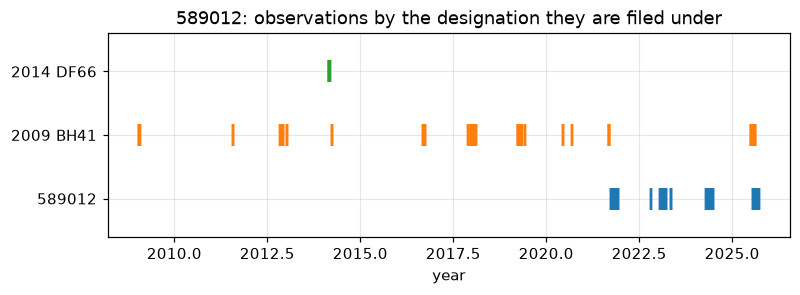

In [3]:
def per_designation(rows):
    table = {}
    for d in sorted({o["designation"] for o in rows}):
        sub = [o for o in rows if o["designation"] == d]
        jd = np.array([o["jd_utc"] for o in sub])
        table[d] = {"obs": len(sub), "nights": len({int(j + 0.5) for j in jd}),
                    "first": Time(jd.min(), format="jd").iso[:10],
                    "last": Time(jd.max(), format="jd").iso[:10],
                    "stations": " ".join(sorted({o["obscode"] for o in sub}))}
    return pd.DataFrame(table).T

print(per_designation(obs))

fig, ax = plt.subplots(figsize=(8, 2.4))
names = ["589012", "2009 BH41", "2014 DF66"]
for k, d in enumerate(names):
    years = [Time(o["jd_utc"], format="jd").decimalyear for o in obs if o["designation"] == d]
    ax.plot(years, [k] * len(years), "|", ms=14, mew=1.5)
ax.set(yticks=range(len(names)), yticklabels=names, xlabel="year",
       title="589012: observations by the designation they are filed under", ylim=(-0.6, 2.6))
plt.show()

The 2014 DF66 discovery is 11 observations on three nights: two Pan-STARRS 1 nights (F51) on
2014 February 26 and 27 and one Spacewatch night (691) on March 7. The 2009 discovery apparition
is nine Spacewatch observations on January 16, 20 and 30.

Those two short arcs are our **A** (2009) and **B** (2014 DF66). Everything else, the later
apparitions that made the orbit precise, is held back until section 7, where it serves as the
check.

All fits below run with the 16 most massive asteroids as perturbers
(`pyroorb.asteroid_perturbers()`). PyRoOrb fits a requested identification in that model from
the first step anyway; putting *every* fit in it means the single-arc and joint fits are in the
same force model, so their χ² can be compared.

In [4]:
pyroorb.asteroid_perturbers()          # every fit from here on: DE440 + GR + 16 asteroids

pair = pyroorb.fetch_observations(["2009 BH41", "2014 DF66"])   # the proposed identification
A = [o for o in pair if o["designation"] == "2009 BH41" and o["jd_utc"] < Time("2009-03-01").jd]
B = [o for o in pair if o["designation"] == "2014 DF66"]


def fit(rows, meta=pair.meta, **kw):
    # gravity only: these are main-belt arcs; a Yarkovsky term is neither expected nor testable
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", pyroorb.UndeterminedOrbitWarning)
        return pyroorb.fit_orbit(pyroorb.Observations(rows, meta), nongrav="none", **kw)


def chi2(f, everything=False):
    # sum over observations of (O-C / sigma)^2, both axes; by default the kept observations only
    rows = f.residuals(included_only=not everything)
    return sum((r["d_ra_arcsec"] / r["sigma_ra"]) ** 2 + (r["d_dec_arcsec"] / r["sigma_dec"]) ** 2
               for r in rows)


def summary(f):
    el, sg = f.elements(), f.element_sigmas()
    return {"kept/total": f"{f.n_observations()}/{f.n_total_observations()}",
            "rms [\"]": round(f.rms_residual(), 3), "chi2": round(chi2(f), 2),
            "dof": f.degrees_of_freedom(), "determined": f.is_determined,
            "a [au]": f"{el['a']:.4f} ± {sg['a']:.1e}", "e": f"{el['e']:.4f} ± {sg['e']:.1e}",
            "i [deg]": f"{el['i']:.3f} ± {sg['i']:.1e}", "U": round(f.uncertainty_parameter(), 1)}


fA, fB = fit(A), fit(B)
print(pd.DataFrame({"A: 2009 BH41 (2009)": summary(fA), "B: 2014 DF66": summary(fB)}).T)

                    kept/total rms ["]  chi2 dof determined            a [au]                 e          i [deg]    U
A: 2009 BH41 (2009)        9/9   0.278  3.86  12       True  2.7706 ± 1.1e-02  0.0774 ± 1.2e-02  4.924 ± 2.7e-02  8.3
B: 2014 DF66             11/11   0.069  2.01  16       True  2.8071 ± 2.7e-02  0.1087 ± 2.1e-02  4.905 ± 1.6e-02  8.9


Each arc alone gives a determined but loose orbit (uncertainty parameter U ≈ 8-9 on the MPC's 0-9
scale). The two orbits look alike: a ≈ 2.77-2.81 au, e ≈ 0.08-0.11, i ≈ 4.9°. That is
suggestive, not proof: thousands of main-belt asteroids share such elements, and a family of
look-alikes is precisely where false identifications come from.

(A note on the observation sets: `A` and `B` carry the fetch's `meta`, so
`fA.linked_designations()` would list all three names even though `fA` contains only 2009 BH41
rows. The designations actually in a fit are best read from its residual rows, as below.)

In [5]:
print("fA.linked_designations():", fA.linked_designations())
print("designations in fA's rows:", sorted({r["designation"] for r in fA.residuals()}))

fA.linked_designations(): ['2009 BH41', '2014 DF66', '589012']
designations in fA's rows: ['2009 BH41']


## 2. Does A predict B?

The classical first test: propagate A's orbit to the dates of B and see whether B falls inside the
predicted uncertainty region. `pyroorb.ephemeris` gives the predicted position as seen from the
observing station and the 1-sigma sky ellipse from the fit's linear covariance. We measure B's
offset along the ellipse's major axis and across it, in units of the ellipse's own sigmas.

In [6]:
def offset_in_ellipse(f, o):
    # the observation o relative to f's prediction: (along, across) in sigmas, and the ephemeris row
    e = pyroorb.ephemeris(f, o["jd_utc"], o["jd_utc"], site=o["obscode"], full=False)[0]
    dE = ((o["ra_deg"] - e["ra_deg"] + 180) % 360 - 180) * np.cos(np.radians(o["dec_deg"])) * 3600
    dN = (o["dec_deg"] - e["dec_deg"]) * 3600
    pa = np.radians(e["unc_pa_deg"])            # major axis, north through east
    along = dE * np.sin(pa) + dN * np.cos(pa)
    across = dE * np.cos(pa) - dN * np.sin(pa)
    return along / e["unc_smaj_arcsec"], across / e["unc_smin_arcsec"], e


rows = []
for o in B:
    al, ac, e = offset_in_ellipse(fA, o)
    rows.append({"date (UTC)": Time(o["jd_utc"], format="jd").iso[:16], "stn": o["obscode"],
                 "1σ ellipse [\"]": f"{e['unc_smaj_arcsec']:.0f} x {e['unc_smin_arcsec']:.0f}",
                 "along [σ]": round(al, 2), "across [σ]": round(ac, 2),
                 "distance [σ]": round(float(np.hypot(al, ac)), 2)})
pred_B = pd.DataFrame(rows)
print(pred_B.to_string(index=False))

      date (UTC) stn 1σ ellipse ["]  along [σ]  across [σ]  distance [σ]
2014-02-26 13:34 F51     11098 x 54      -0.43       -0.28          0.51
2014-02-26 13:52 F51     11099 x 54      -0.43       -0.29          0.51
2014-02-26 14:10 F51     11100 x 54      -0.43       -0.29          0.51
2014-02-26 14:27 F51     11100 x 54      -0.43       -0.29          0.51
2014-02-27 11:44 F51     11147 x 54      -0.43       -0.29          0.51
2014-02-27 12:02 F51     11148 x 54      -0.43       -0.29          0.52
2014-02-27 12:19 F51     11148 x 54      -0.43       -0.29          0.52
2014-02-27 12:37 F51     11149 x 54      -0.43       -0.29          0.51
2014-03-07 07:18 691     11501 x 58      -0.43       -0.27          0.51
2014-03-07 07:44 691     11502 x 58      -0.43       -0.27          0.51
2014-03-07 08:09 691     11503 x 58      -0.43       -0.27          0.51


2014 DF66 sits about half a sigma from where the 2009 arc puts it. But look at the ellipse: about
**11,000" by 54"** (3° by 1 arcminute, 1 sigma). Five years after a two-week arc, the position
*along* the orbit is barely known (it is the mean anomaly, which depends on the poorly known
semi-major axis), while the position *across* the track is still pinned to about an arcminute.
A short-arc prediction is a long, thin line on the sky.

So "B is inside the ellipse" is weak evidence by itself: a 3-sigma ellipse of this size covers
more than a square degree near the ecliptic, where main-belt asteroids of this brightness are
plentiful. The test has power only across the track. The sky picture:

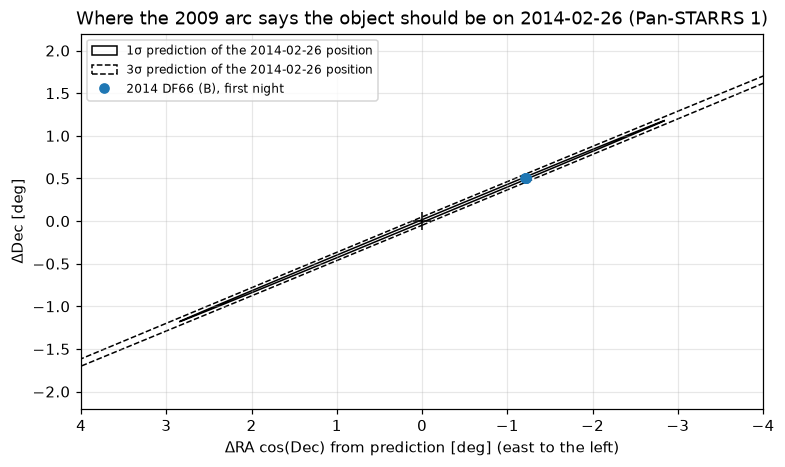

In [7]:
def sky_plot(fpred, t_jd, site, groups, title, n_sigma=(1, 3)):
    # predicted position + n-sigma ellipses of fpred at one time, and observation groups around it
    e = pyroorb.ephemeris(fpred, t_jd, t_jd, site=site, full=False)[0]
    ra0, dec0 = e["ra_deg"], e["dec_deg"]
    fig, ax = plt.subplots(figsize=(8, 5))
    for k in n_sigma:
        # in (east, north) data coordinates the major axis at position angle PA (north through
        # east) points at 90 - PA from the +x axis; the x axis is inverted only for display
        ax.add_patch(Ellipse((0, 0), 2 * k * e["unc_smaj_arcsec"] / 3600,
                             2 * k * e["unc_smin_arcsec"] / 3600, angle=90 - e["unc_pa_deg"],
                             fill=False, lw=1, ls="-" if k == 1 else "--", color="k",
                             label=f"{k}σ prediction of the {Time(t_jd, format='jd').iso[:10]} position"))
    for label, pts, style in groups:
        pts = [o for o in pts if abs(o["jd_utc"] - t_jd) < 0.5]      # the same night only
        if not pts:
            continue
        x = [((o["ra_deg"] - ra0 + 180) % 360 - 180) * np.cos(np.radians(dec0)) for o in pts]
        y = [o["dec_deg"] - dec0 for o in pts]
        ax.plot(x, y, style, label=label, ms=6)
    ax.plot(0, 0, "k+", ms=12)
    ax.set(xlabel="ΔRA cos(Dec) from prediction [deg] (east to the left)",
           ylabel="ΔDec [deg]", title=title)
    ax.set(xlim=(4, -4), ylim=(-2.2, 2.2))                     # east to the left
    ax.set_aspect("equal")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()


sky_plot(fA, B[0]["jd_utc"], B[0]["obscode"],
         [("2014 DF66 (B), first night", B, "o")],
         "Where the 2009 arc says the object should be on 2014-02-26 (Pan-STARRS 1)")

## 3. The joint fit, and the identification penalty

Now fit A and B as one object. If they are the same asteroid, one orbit should fit both arcs as
well as each arc's own orbit fits it, give or take the noise. The natural statistic is the
**identification penalty**

$$\Delta\chi^2 = \chi^2_{A+B} - \chi^2_A - \chi^2_B .$$

Why compare it with a χ² distribution with **6 degrees of freedom**? Fitted separately, the two arcs
use 6 + 6 = 12 parameters (two orbits); fitted jointly, 6 (one orbit). The joint fit is the
separate fit with six constraints added: B's orbit must equal A's propagated orbit. With Gaussian
errors and correctly scaled weights, the χ² cost of six linear constraints that are true is
distributed as χ²₆, so Δχ² ≫ 13 (the 95th percentile) or ≫ 20 (99.7 %) says the constraint is false.
(When one arc determines fewer than six quantities, as a single night does in section 5, the
number of independent constraints, and hence the dof, is smaller.)

In [8]:
fAB = fit(A + B)
print(pd.DataFrame({"A alone": summary(fA), "B alone": summary(fB), "A + B jointly": summary(fAB)}).T)

dchi2 = chi2(fAB) - chi2(fA) - chi2(fB)
print(f"\nidentification penalty Δχ² = {chi2(fAB):.2f} - {chi2(fA):.2f} - {chi2(fB):.2f} = {dchi2:.2f}"
      f"   P(χ²₆ > Δχ²) = {chi2_dist.sf(dchi2, 6):.2f}")
print(f"χ²₆ thresholds: 95 % {chi2_dist.ppf(0.95, 6):.1f}, 99.7 % {chi2_dist.ppf(0.997, 6):.1f}")
print("observations rejected by the joint fit:", fAB.n_excluded())

              kept/total rms ["]   chi2 dof determined            a [au]                 e          i [deg]    U
A alone              9/9   0.278   3.86  12       True  2.7706 ± 1.1e-02  0.0774 ± 1.2e-02  4.924 ± 2.7e-02  8.3
B alone            11/11   0.069   2.01  16       True  2.8071 ± 2.7e-02  0.1087 ± 2.1e-02  4.905 ± 1.6e-02  8.9
A + B jointly      20/20   0.226  10.27  34       True  2.7754 ± 4.3e-05  0.0822 ± 1.5e-04  4.918 ± 2.2e-04  4.8

identification penalty Δχ² = 10.27 - 3.86 - 2.01 = 4.40   P(χ²₆ > Δχ²) = 0.62
χ²₆ thresholds: 95 % 12.6, 99.7 % 19.8
observations rejected by the joint fit: 0


All 20 observations are kept, the joint rms (0.23") is no worse than the 2009 arc alone, and the
penalty is a few units of χ², an ordinary draw from χ²₆ with the weights as they are. The joint orbit also pins down
the semi-major axis an order of magnitude better than either arc (U drops from 8-9 to about 5).

**A caveat on the scale.** PyRoOrb's observation weights are deliberately conservative (they are
floored, never shrunk by the fit), so χ²/dof is well below 1 here. The raw Δχ² is therefore
smaller than it would be with weights matched to the scatter, and the raw test is lenient. The
obvious calibration, dividing by the separate fits' own χ²/dof, goes too far the other way:
observations within one night share errors (the same reference stars, the same timing), so the
scatter *within* a night understates the error of a night as a whole, and the two arcs are
joined night against night. Where does the extra χ² come from?

In [9]:
s2 = (chi2(fA) + chi2(fB)) / (fA.degrees_of_freedom() + fB.degrees_of_freedom())
print(f"separate fits' χ²/dof = {s2:.2f};  rescaled Δχ² = {dchi2 / s2:.1f}, "
      f"P(χ²₆ > that) = {chi2_dist.sf(dchi2 / s2, 6):.3f}")

res = fAB.residuals()
for d, f_alone in (("2009 BH41", fA), ("2014 DF66", fB)):
    side = [r for r in res if r["designation"] == d]
    c = sum((r["d_ra_arcsec"] / r["sigma_ra"]) ** 2 + (r["d_dec_arcsec"] / r["sigma_dec"]) ** 2 for r in side)
    print(f"{d}: χ² {chi2(f_alone):.2f} on its own orbit -> {c:.2f} on the joint orbit")

separate fits' χ²/dof = 0.21;  rescaled Δχ² = 21.0, P(χ²₆ > that) = 0.002
2009 BH41: χ² 3.86 on its own orbit -> 4.35 on the joint orbit
2014 DF66: χ² 2.01 on its own orbit -> 5.92 on the joint orbit


Most of the increase is on the Pan-STARRS side, whose 0.07" internal scatter is tiny next to its
0.2" weights: the joint orbit shifts the three 2014 nights against each other by about 0.2"
(see the residual plot below), which is small in arcseconds and large in units of the within-night
scatter. So the honest reading is a range: the raw penalty (P ≈ 0.6) is too lenient, the fully
rescaled one (P ≈ 0.002) too strict because it treats every observation in a night as an
independent measurement. A true identification sits somewhere between, near the edge of the
strict test; as we shall see, the false pairs miss by orders of magnitude, so the
ambiguity of scale does not decide anything here.

The residuals of the joint fit, arc by arc. A wrong identification typically shows up as a trend or
an offset in one arc; here both arcs scatter about zero at the level of their own astrometry
(Spacewatch ±0.3", Pan-STARRS ±0.1").

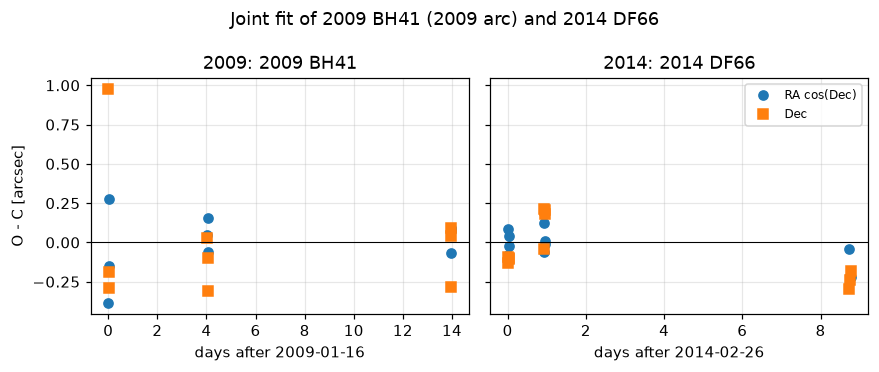

In [10]:
def residual_panels(f, title):
    res = f.residuals()
    groups = sorted({Time(r["jd_utc"], format="jd").datetime.year for r in res})
    fig, axes = plt.subplots(1, len(groups), figsize=(4 * len(groups), 3.4), sharey=True, squeeze=False)
    for ax, yr in zip(axes[0], groups):
        sub = [r for r in res if Time(r["jd_utc"], format="jd").datetime.year == yr]
        t0 = min(r["jd_utc"] for r in sub)
        for key, mk, lab in (("d_ra_arcsec", "o", "RA cos(Dec)"), ("d_dec_arcsec", "s", "Dec")):
            for inc, fill in ((True, None), (False, "none")):
                pts = [r for r in sub if r["included"] == inc]
                if pts:
                    ax.plot([r["jd_utc"] - t0 for r in pts], [r[key] for r in pts], mk,
                            mfc=fill, label=lab + ("" if inc else " (rejected)"))
        ax.axhline(0, color="k", lw=0.7)
        desig = ", ".join(sorted({r["designation"] for r in sub}))
        ax.set(title=f"{yr}: {desig}", xlabel=f"days after {Time(t0, format='jd').iso[:10]}")
    axes[0][0].set_ylabel("O - C [arcsec]")
    axes[0][-1].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


residual_panels(fAB, "Joint fit of 2009 BH41 (2009 arc) and 2014 DF66")

## 4. A false pair: a neighbour seen in the same weeks

Now the dangerous case. A decoy should be something a careless identification could plausibly
pick: an asteroid on a similar orbit, near A's predicted position, of similar brightness, observed
by the same surveys in the same weeks of 2014.

**Finding decoys.** We ask SBDB for every asteroid with elements close to A's
(a within 0.07 au, e within 0.05, i within 0.9°, node within 10°), compute a rough two-body
position for each on 2014-02-26 from SBDB's elements, and keep those within 2.5° of A's
prediction. Two-body propagation over twelve years is crude (it puts 589012 itself 1-2° from
where it really was), so this is only a shortlist; what counts is the real astrometry, which we
then fetch from the MPC.

In [11]:
elA = fA.elements()
cdata = {"AND": [f"a|RG|{elA['a'] - 0.07:.3f}|{elA['a'] + 0.07:.3f}",
                 f"e|RG|{max(elA['e'] - 0.05, 0):.3f}|{elA['e'] + 0.05:.3f}",
                 f"i|RG|{elA['i'] - 0.9:.2f}|{elA['i'] + 0.9:.2f}",
                 f"om|RG|{elA['asc_node'] - 10:.1f}|{elA['asc_node'] + 10:.1f}"]}
query = urllib.parse.urlencode({"fields": "pdes,epoch,a,e,i,om,w,ma,H", "sb-kind": "a",
                                "sb-cdata": json.dumps(cdata)})
q = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb_query.api?" + query, timeout=120))
el = {k: np.array([row[j] for row in q["data"]]) for j, k in enumerate(q["fields"])}
print(f"{q['count']} SBDB asteroids with A-like elements")


def two_body_radec(el, t_jd, site_xyz):
    # geocentric RA/Dec [deg] of every element set at t_jd, Kepler orbit about the Sun
    a, e = el["a"].astype(float), el["e"].astype(float)
    inc, node, peri, M0 = (np.radians(el[k].astype(float)) for k in ("i", "om", "w", "ma"))
    M = M0 + 0.01720209895 / a ** 1.5 * (t_jd - el["epoch"].astype(float))
    E = M.copy()
    for _ in range(30):
        E -= (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
    nu = 2 * np.arctan2(np.sqrt(1 + e) * np.sin(E / 2), np.sqrt(1 - e) * np.cos(E / 2))
    r, u = a * (1 - e * np.cos(E)), peri + nu
    x = r * (np.cos(node) * np.cos(u) - np.sin(node) * np.sin(u) * np.cos(inc))
    y = r * (np.sin(node) * np.cos(u) + np.cos(node) * np.sin(u) * np.cos(inc))
    z = r * np.sin(u) * np.sin(inc)
    eps = np.radians(23.43928111)                           # ecliptic -> equatorial
    g = np.vstack([x, y * np.cos(eps) - z * np.sin(eps), y * np.sin(eps) + z * np.cos(eps)]).T - site_xyz
    return np.degrees(np.arctan2(g[:, 1], g[:, 0])) % 360, np.degrees(np.arcsin(g[:, 2] / np.linalg.norm(g, axis=1)))


t0 = B[0]["jd_utc"]
earth = pyroorb.body_states("earth", t0)[0, :3]           # heliocentric equatorial, au
ra, dec = two_body_radec(el, t0, earth)
p = pyroorb.ephemeris(fA, t0, t0, site="500", full=False)[0]
sep = np.degrees(np.arccos(np.clip(np.sin(np.radians(dec)) * np.sin(np.radians(p["dec_deg"]))
                                   + np.cos(np.radians(dec)) * np.cos(np.radians(p["dec_deg"]))
                                   * np.cos(np.radians(ra - p["ra_deg"])), -1, 1)))
shortlist = [el["pdes"][j] for j in np.argsort(sep) if sep[j] < 2.5 and el["pdes"][j] != "589012"]
print(f"{len(shortlist)} within 2.5° of A's prediction (two-body):", ", ".join(shortlist))

1794 SBDB asteroids with A-like elements
19 within 2.5° of A's prediction (two-body): 660007, 597793, 296217, 2017 YL49, 2025 UD68, 2018 BU117, 2025 UQ52, 2020 PL22, 872095, 2016 QH145, 2021 VR117, 2020 PQ126, 851299, 2025 UE95, 300734, 830213, 602107, 2025 TL43, 2025 UO54


For each candidate, fetch its astrometry and keep what it has between ten days before B's first
night and ten days after B's last. Where it does, measure that observation against A's prediction
just as we measured 2014 DF66.

In [12]:
family = {d for alt in sb["object"]["des_alt"] for d in alt.values()} | {"589012"}
window = (B[0]["jd_utc"] - 10, B[-1]["jd_utc"] + 10)
decoys, rows = {}, []
for d in shortlist:
    try:
        ob = pyroorb.fetch_observations(d)
    except pyroorb.FetchError as ex:
        print(d, "not fetched:", ex)
        continue
    w = [o for o in ob if window[0] < o["jd_utc"] < window[1] and o["designation"] not in family]
    if not w:
        continue
    decoys[d] = w
    al, ac, _ = offset_in_ellipse(fA, w[0])
    mags = [o["mag"] for o in w if o["mag"] is not None]
    rows.append({"decoy": d, "obs": len(w), "nights": len({int(o["jd_utc"] + .5) for o in w}),
                 "stations": " ".join(sorted({o["obscode"] for o in w})),
                 "mag": round(float(np.median(mags)), 1) if mags else None,
                 "along [σ]": round(al, 2), "across [σ]": round(ac, 1)})
cand = pd.DataFrame(rows).sort_values(["nights", "obs"], ascending=False)
print(f"{len(decoys)} of {len(shortlist)} candidates were observed in the window "
      f"(2014 DF66 itself: 11 obs, 3 nights, F51 691, mag ~21.2, along {pred_B['along [σ]'][0]}σ, "
      f"across {pred_B['across [σ]'][0]}σ)")
print(cand.to_string(index=False))

5 of 19 candidates were observed in the window (2014 DF66 itself: 11 obs, 3 nights, F51 691, mag ~21.2, along -0.43σ, across -0.28σ)
 decoy  obs  nights stations  mag  along [σ]  across [σ]
300734    8       2      F51 20.6      -0.56        39.0
660007    7       2  691 F51 21.6       0.27        31.7
602107    7       2      F51 21.7      -0.34        73.2
296217    4       1      F51 21.1      -0.10       -24.4
830213    3       1      F51 21.9       0.97       -50.0


Several real asteroids were measured by the same two telescopes within days of 2014 DF66, at the
same brightness, and they all sit comfortably **inside the long axis** of A's prediction (|along|
< 1σ). Every one misses **across** the track by tens of sigmas. Position along the track cannot
tell them from the true object; position across it can.

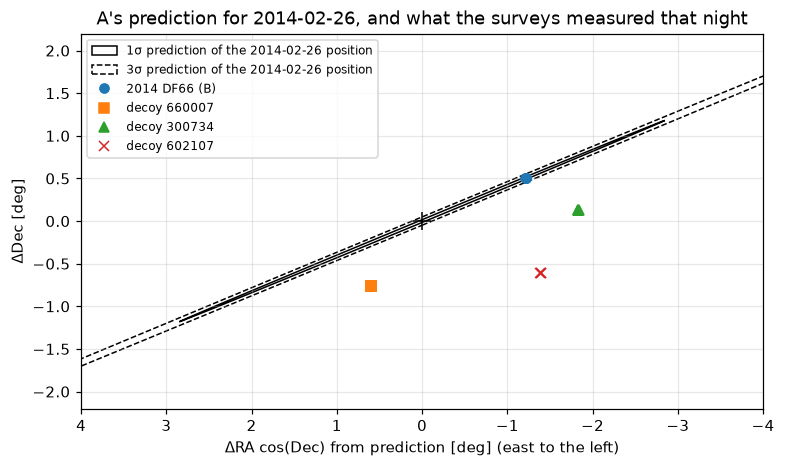

In [13]:
sky_plot(fA, B[0]["jd_utc"], B[0]["obscode"],
         [("2014 DF66 (B)", B, "o")] +
         [(f"decoy {d}", w, m) for (d, w), m in zip(decoys.items(), "sv^Dx<>p")],
         "A's prediction for 2014-02-26, and what the surveys measured that night")

**The joint fits.** Take the two decoys most like 2014 DF66 (the most nights in the window) and
fit each jointly with A, exactly as we did with B. The decoy and A are fetched together with
`fetch_observations(["2009 BH41", decoy])`, the way a proposed identification is requested.

Because `fit_orbit` rejects outliers, the χ² on the kept observations alone can look fine for a
false pair: the fit can simply throw away one side. So we record two things. First, what the
joint fit rejected, counted in observations and in **whole nights** (a station's tracklet dropped
entirely). Second, the penalty when nothing may be dropped: `pyroorb.refit(joint, include=[True]
* n)` solves again on every observation of both arcs, with no rejection, starting from the joint
fit's orbit. That χ² is a local minimum reached from there, so it is the price of the
identification as fitted, not a proof that no better all-inclusive orbit exists; the across-track
misses above say the same thing from the prediction side. Each penalty is also shown rescaled by
the separate fits' χ²/dof of section 3 (the strict reading).

In [14]:
def rejected_nights(f):
    # {designation: "n obs, k whole nights"}: what a fit rejected, by designation
    nights, out = {}, {}
    for r in f.residuals():
        nights.setdefault((r["designation"], r["obscode"], int(r["jd_utc"] + 0.5)), []).append(r["included"])
    for (d, _, _), inc in nights.items():
        n_obs, n_whole = out.get(d, (0, 0))
        out[d] = (n_obs + inc.count(False), n_whole + (not any(inc)))
    return {d: f"{n} obs, {w} whole night{'' if w == 1 else 's'}" for d, (n, w) in out.items() if n}


def judge(label, a_rows, b_rows, meta, fa, dof=6):
    fb, fj = fit(b_rows, meta), fit(a_rows + b_rows, meta)
    fin = pyroorb.refit(fj, include=[True] * fj.n_total_observations())   # nothing may be dropped
    pen = chi2(fin) - chi2(fa) - chi2(fb)
    sub = "₆" if dof == 6 else "₄"
    return fj, {"pair": label, "kept/total": f"{fj.n_observations()}/{fj.n_total_observations()}",
                "rms kept [\"]": round(fj.rms_residual(), 2),
                "rejected": "; ".join(f"{d}: {v}" for d, v in rejected_nights(fj).items()) or "none",
                "rms none dropped [\"]": f"{fin.rms_residual():.3g}",
                "Δχ² none dropped": f"{pen:.3g}", f"P(χ²{sub})": f"{chi2_dist.sf(pen, dof):.2g}",
                "rescaled": f"{pen / s2:.3g}", "P resc.": f"{chi2_dist.sf(pen / s2, dof):.2g}"}


chosen = list(cand["decoy"][:2])
pairs, table = {}, [judge("A + 2014 DF66 (true)", A, B, pair.meta, fA)[1]]
for d in chosen:
    pmeta = pyroorb.fetch_observations(["2009 BH41", d]).meta
    pairs[d], row = judge(f"A + {d} (decoy)", A, decoys[d], pmeta, fA)
    table.append(row)
decoy_table = pd.DataFrame(table)
print(decoy_table.drop(columns="rejected").to_string(index=False))
print("\nwhat the rejecting joint fit dropped:")
for r in table:
    print(f"  {r['pair']}: {r['rejected']}")
print("(rows of 660007 are filed under its provisional designation, 1995 CB9)" if "660007" in chosen else "")

                pair kept/total  rms kept ["] rms none dropped ["] Δχ² none dropped P(χ²₆) rescaled P resc.
A + 2014 DF66 (true)      20/20          0.23                0.226              4.4   0.62       21  0.0019
  A + 300734 (decoy)       9/17          0.28                 12.3         7.71e+04      0 3.67e+05       0
  A + 660007 (decoy)      10/16          0.27                 23.5         5.34e+04      0 2.54e+05       0

what the rejecting joint fit dropped:
  A + 2014 DF66 (true): none
  A + 300734 (decoy): 300734: 8 obs, 2 whole nights
  A + 660007 (decoy): 2009 BH41: 3 obs, 1 whole night; 1995 CB9: 3 obs, 1 whole night
(rows of 660007 are filed under its provisional designation, 1995 CB9)


This is the instructive part. **The joint fit does not fail.** Given two short arcs that are not
the same object, the least-squares fit with outlier rejection still converges to a determined orbit
with a respectable rms on what it kept: it gets there by rejecting observations, often a whole
night or a whole side of the pair. Read only the rms and you would accept it.

What exposes the false pair is *what was thrown away* and *what it costs to keep it*: the
rejecting fit drops whole nights of a coherent arc, or a whole side of the pair, and when nothing
may be dropped the penalty is off any χ²₆ scale, raw or rescaled. The true pair loses nothing,
and its no-rejection penalty is the same as in section 3.

The residuals of the first decoy pair, rejected points open:

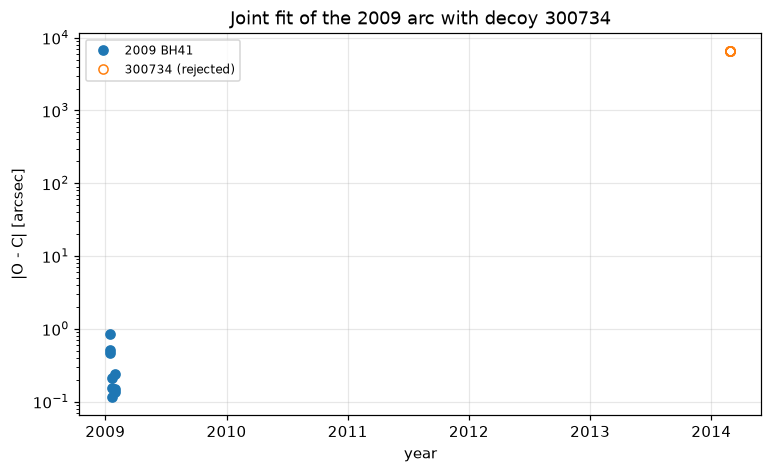

In [15]:
d0 = chosen[0]
res = pairs[d0].residuals()
fig, ax = plt.subplots()
for desig in sorted({r["designation"] for r in res}):
    for inc, fill in ((True, None), (False, "none")):
        pts = [r for r in res if r["designation"] == desig and r["included"] == inc]
        if pts:
            ax.semilogy([Time(r["jd_utc"], format="jd").decimalyear for r in pts],
                        [max(np.hypot(r["d_ra_arcsec"], r["d_dec_arcsec"]), 1e-3) for r in pts], "o",
                        mfc=fill, label=f"{desig}" + ("" if inc else " (rejected)"))
ax.set(xlabel="year", ylabel="|O - C| [arcsec]", title=f"Joint fit of the 2009 arc with decoy {d0}")
ax.legend(fontsize=8)
plt.show()

## 5. The edge: one night on one side

Identifications are often far thinner than three nights against three nights. A survey's isolated
tracklet (a few detections within an hour) gets linked to a known object years away. How close to
the edge is that? Cut 2014 DF66 down to its first night: four Pan-STARRS observations spanning 53
minutes.

A single night does not determine an orbit (the fit says so); it measures a position and a rate of
motion, four numbers. So the joint fit adds at most four independent constraints and the penalty
is compared with χ²₄ rather than χ²₆. For the decoys we use their own Pan-STARRS tracklet from
the same night or the next.

In [16]:
def first_night(rows, station="F51"):
    rows = [o for o in rows if o["obscode"] == station]
    return [o for o in rows if int(o["jd_utc"] + .5) == int(rows[0]["jd_utc"] + .5)] if rows else []


B1 = first_night(B)
fB1 = fit(B1)
print(f"B1: {len(B1)} obs over {(B1[-1]['jd_utc'] - B1[0]['jd_utc']) * 1440:.0f} min; "
      f"determined on its own: {fB1.is_determined}")

table = []
for label, rows, meta in [("A + 2014 DF66 night 1 (true)", B1, pair.meta)] + [
        (f"A + {d} one night (decoy)", first_night(decoys[d]),
         pyroorb.fetch_observations(["2009 BH41", d]).meta) for d in decoys]:
    if len(rows) < 3:
        continue
    al, ac, _ = offset_in_ellipse(fA, rows[0])
    fj, row = judge(label, A, rows, meta, fA, dof=4)
    row["across [σ]"] = round(ac, 1)
    table.append(row)
edge = pd.DataFrame(table)
print(edge.drop(columns="rejected").to_string(index=False))
print("\nwhat the rejecting joint fit dropped:")
for r in table:
    print(f"  {r['pair']}: {r['rejected']}")

B1: 4 obs over 53 min; determined on its own: False


                        pair kept/total  rms kept ["] rms none dropped ["] Δχ² none dropped   P(χ²₄) rescaled P resc.  across [σ]
A + 2014 DF66 night 1 (true)      13/13          0.24                0.243            0.448     0.98     2.14    0.71        -0.3
A + 660007 one night (decoy)      10/13          0.27                 4.81         1.67e+03        0 7.95e+03       0        31.7
A + 296217 one night (decoy)      10/13          0.26                 3.17              720 1.3e-154 3.43e+03       0       -24.4
A + 300734 one night (decoy)       9/13          0.28                 6.51         3.09e+03        0 1.47e+04       0        39.0
A + 830213 one night (decoy)       9/12          0.28                 5.65         2.13e+03        0 1.02e+04       0       -50.0
A + 602107 one night (decoy)       9/12          0.28                 14.1         1.34e+04        0 6.36e+04       0        73.2

what the rejecting joint fit dropped:
  A + 2014 DF66 night 1 (true): none
  A + 660007 o

The true single night joins cleanly: nothing rejected, Δχ² well inside χ²₄, raw or rescaled.
The decoy tracklets do not: with nothing allowed to drop, every one costs a penalty of
hundreds to thousands (720 to about 13,000).

But this is the edge, and the rejecting fit shows it. Two of the decoy tracklets, 660007's and
296217's, *are* absorbed by `fit_orbit`: it keeps the four decoy observations and gives up a
**whole 2009 night** (one of A's three, 3 observations), and what remains fits at 0.26-0.27",
about as well as the true pair. With three nights on one side and one on the other, the rejecting
fit cannot by itself tell whether the decoy is wrong or the 2009 night is, and a reader of the rms
alone would accept these. Two numbers settle it: a coherent three-night discovery arc has to lose
a whole night of its own to take the tracklet, and keeping that night costs Δχ² of about 700 (296217) and 1,700 (660007).
The other decoys are absorbed only by rejecting the decoy tracklet itself.

The true identification's margin is entirely the **across-track** width of A's prediction, about
1' (1σ) in 2014: the decoys missed by tens of those. Along the track there is no discrimination
at all.

How does that width evolve? A's 1-sigma ellipse, seen from the geocentre, from 2009 to 2016:

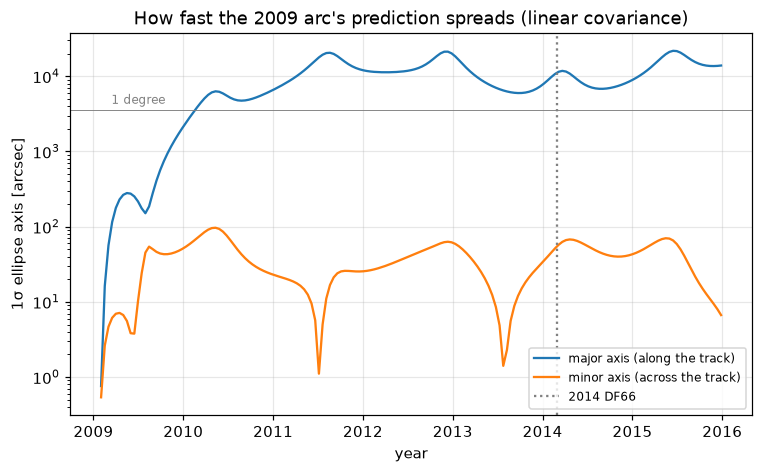

In [17]:
grid = pyroorb.ephemeris(fA, "2009-02-01", "2016-01-01", step=15, site="500", full=False)
yr = [Time(g["jd_utc"], format="jd").decimalyear for g in grid]
fig, ax = plt.subplots()
ax.semilogy(yr, [g["unc_smaj_arcsec"] for g in grid], label="major axis (along the track)")
ax.semilogy(yr, [g["unc_smin_arcsec"] for g in grid], label="minor axis (across the track)")
ax.axvline(Time(B[0]["jd_utc"], format="jd").decimalyear, color="grey", ls=":", label="2014 DF66")
ax.axhline(3600, color="grey", lw=0.6)
ax.text(2009.2, 4300, "1 degree", color="grey", fontsize=8)
ax.set(xlabel="year", ylabel="1σ ellipse axis [arcsec]",
       title="How fast the 2009 arc's prediction spreads (linear covariance)")
ax.legend(fontsize=8)
plt.show()

The along-track uncertainty reaches a degree within about a year and a half; after that it
swings with the viewing geometry (the same error along the orbit spans more sky near opposition,
when the asteroid is closest) between about two and six degrees. At that size the linear ellipse
is only an approximation: the real region of possible positions curves along the orbit. The
across-track width also swings with the geometry, between about 1" and 100". A
single tracklet years away is linkable as long as the across-track band is narrow compared with
the spacing of other asteroids moving the same way; the band widens with every additional year,
and the 3σ region along the track already holds many unrelated objects.

More data on the A side changes this completely. Add the 2011-2013 nights filed under 2009 BH41
(one Pan-STARRS night in 2011 and five nights in 2012-13, from before 2014 DF66 was found) and
predict the same Pan-STARRS night:

In [18]:
A2 = [o for o in pair if o["designation"] == "2009 BH41" and o["jd_utc"] < Time("2014-01-01").jd]
fA2 = fit(A2)
al, ac, e = offset_in_ellipse(fA2, B1[0])
print(f"A2: {len(A2)} obs, {fA2.n_oppositions()} oppositions, U = {fA2.uncertainty_parameter():.1f}")
print(f"prediction for 2014-02-26: 1σ ellipse {e['unc_smaj_arcsec']:.1f}\" x {e['unc_smin_arcsec']:.2f}\"; "
      f"2014 DF66 is at {al:+.2f}σ along, {ac:+.2f}σ across")
fA2B1 = fit(A2 + B1)
pen = chi2(fA2B1, everything=True) - chi2(fA2) - chi2(fB1)
print(f"joint fit with the single night: {fA2B1.n_observations()}/{fA2B1.n_total_observations()} kept, "
      f"Δχ² = {pen:.2f}, P(χ²₄) = {chi2_dist.sf(pen, 4):.2f}; rescaled {pen / s2:.1f}, "
      f"P = {chi2_dist.sf(pen / s2, 4):.2f}")
for d in list(decoys)[:3]:
    al, ac, _ = offset_in_ellipse(fA2, decoys[d][0])
    print(f"   decoy {d}: {al:+.0f}σ along, {ac:+.0f}σ across")

A2: 28 obs, 3 oppositions, U = 3.9
prediction for 2014-02-26: 1σ ellipse 22.4" x 0.16"; 2014 DF66 is at -0.79σ along, -0.01σ across
joint fit with the single night: 32/32 kept, Δχ² = 1.18, P(χ²₄) = 0.88; rescaled 5.6, P = 0.23
   decoy 660007: +347σ along, +10546σ across
   decoy 296217: +158σ along, -8446σ across
   decoy 300734: -68σ along, +13495σ across


With three oppositions behind it, the prediction shrinks from degrees to tens of arcseconds by a
fraction of an arcsecond, and a single tracklet becomes an unambiguous match; the decoys are now
thousands of sigmas outside the ellipse across the track and tens to hundreds along it.

## 6. Check against JPL

Three independent checks of what we did:

1. **The identification itself.** SBDB lists 2014 DF66 among 589012's designations (section 1): the
   MPC and JPL accept the pair we accepted. None of our decoys is listed there.
2. **The orbit from all the data.** Fit every observation of 589012 and compare the elements with
   SBDB's, at SBDB's epoch.
3. **The joint 2009 + 2014 orbit as a prediction.** If the identification is right, the A + B orbit
   alone should predict the later apparitions. We compare it with JPL Horizons' positions (from
   JPL's full-data orbit) in 2017, 2019 and 2025.

In [19]:
print("decoys listed as 589012 designations in SBDB:", sorted(set(chosen) & family) or "none")

fall = fit(list(pair))
epoch = Time(float(sb["orbit"]["epoch"]), format="jd", scale="tdb")
mine = pyroorb.osculating_elements(pyroorb.propagate(fall, epoch)[0], epoch)
jpl = {e["name"]: (float(e["value"]), float(e["sigma"])) for e in sb["orbit"]["elements"]}
print(f"\nall data: {fall.n_observations()}/{fall.n_total_observations()} observations kept, "
      f"rms {fall.rms_residual():.3f}\"  (JPL: {sb['orbit']['n_obs_used']} used, "
      f"normalized rms {float(sb['orbit']['rms']):.2f})")
rows = []
for k, j in (("a", "a"), ("e", "e"), ("i", "i"), ("asc_node", "om"), ("arg_per", "w"), ("M", "ma")):
    rows.append({"element": k, "PyRoOrb": f"{mine[k]:.8f}", "JPL": f"{jpl[j][0]:.8f}",
                 "JPL 1σ": f"{jpl[j][1]:.1e}", "difference [JPL σ]": round((mine[k] - jpl[j][0]) / jpl[j][1], 2)})
print(f"elements at JD {epoch.jd} TDB (ecliptic J2000)")
print(pd.DataFrame(rows).to_string(index=False))

decoys listed as 589012 designations in SBDB: none



all data: 280/281 observations kept, rms 0.274"  (JPL: 256 used, normalized rms 0.58)
elements at JD 2461200.5 TDB (ecliptic J2000)
 element      PyRoOrb          JPL  JPL 1σ  difference [JPL σ]
       a   2.77420077   2.77420075 2.1e-08                0.63
       e   0.07994934   0.07994933 4.4e-08                0.32
       i   4.92028318   4.92028335 4.2e-06               -0.04
asc_node 103.16368281 103.16381032 5.6e-05               -2.26
 arg_per 328.29938589 328.29927241 6.4e-05                1.78
       M 332.02740945 332.02739880 3.1e-05                0.34


The full-data orbit matches JPL's to within about two of JPL's own (very small) sigmas in
every element. The remaining differences come from the observation sets and weights (JPL uses
its own selection and its own error model), not from the identification.

Now the prediction test of the 2009 + 2014 orbit:

In [20]:
def horizons_radec(designation, jd_utc):
    query = urllib.parse.urlencode({"format": "json", "COMMAND": f"'{designation};'",
                                    "EPHEM_TYPE": "OBSERVER", "CENTER": "'500@399'",
                                    "TLIST": f"'{jd_utc}'", "TLIST_TYPE": "JD", "TIME_TYPE": "UT",
                                    "QUANTITIES": "'1'", "ANG_FORMAT": "DEG", "EXTRA_PREC": "YES",
                                    "CSV_FORMAT": "YES"})
    txt = json.load(urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?" + query,
                                           timeout=60))["result"]
    line = txt.split("$$SOE")[1].split("$$EOE")[0].strip()
    return [float(x) for x in line.split(",")[3:5]]     # astrometric RA, Dec (ICRF), deg


rows = []
for date in ("2017-12-15", "2019-05-01", "2025-08-15"):
    jd = Time(date).jd
    ra_j, dec_j = horizons_radec("589012", jd)
    al, ac, e = offset_in_ellipse(fAB, {"jd_utc": jd, "obscode": "500", "ra_deg": ra_j, "dec_deg": dec_j})
    dE = ((ra_j - e["ra_deg"] + 180) % 360 - 180) * np.cos(np.radians(dec_j)) * 3600
    dN = (dec_j - e["dec_deg"]) * 3600
    rows.append({"date": date, "JPL - A+B [\"]": f"{np.hypot(dE, dN):.1f}",
                 "A+B 1σ ellipse [\"]": f"{e['unc_smaj_arcsec']:.0f} x {e['unc_smin_arcsec']:.2f}",
                 "along [σ]": round(al, 2), "across [σ]": round(ac, 2)})
print("JPL Horizons (all data) against the orbit from the 2009 and 2014 arcs alone, geocentric")
print(pd.DataFrame(rows).to_string(index=False))

JPL Horizons (all data) against the orbit from the 2009 and 2014 arcs alone, geocentric
      date JPL - A+B ["] A+B 1σ ellipse ["]  along [σ]  across [σ]
2017-12-15          21.2         136 x 1.20       0.16       -0.54
2019-05-01          15.5          38 x 0.51       0.41        0.68
2025-08-15          98.8         282 x 1.24       0.35       -0.37


The two-arc orbit predicts the 2017-2025 apparitions to within its own uncertainty ellipse
(tens of arcseconds along the track, about an arcsecond across). The later observations, all
of which were found and linked because of this identification, confirm it.

## Takeaways

* **Fetching an identified pair.** `fetch_observations` on either designation returns the whole
  merged object from the MPC; each record's `designation` still says which name the row is filed
  under, so the original discoveries can be separated and the identification re-tested.
* **Prediction is necessary, not sufficient.** Five years after a two-week arc, A's 1σ prediction
  for 2014 DF66 was a strip about 3° long and 1' wide. The true object sat at about half a sigma,
  but so, along the track, did several real neighbours of the same brightness, observed by the
  same telescopes that week. Only the across-track direction discriminated (tens of sigmas).
* **The joint fit and its penalty.** The true pair joins with every observation kept and an
  identification penalty Δχ² of a few units, an ordinary χ²₆ draw (the six constraints that
  turn two orbits into one) with PyRoOrb's weights, and near the edge only under the strictest
  rescaling; the decoys' penalties were larger by orders of magnitude.
* **Outlier rejection hides false pairs.** A decoy pair does not make the fit fail: it converges
  to a low-rms orbit by rejecting a night or a whole side. Judge an identification by what was
  rejected (whole nights of a coherent arc are the alarm) and by Δχ² with nothing dropped
  (`pyroorb.refit` with every observation included), never by the rms of the kept ones.
* **One tracklet on one side** is the edge. The true one joined cleanly, but two of five decoy
  tracklets were also absorbed by the rejecting fit, at the same rms, by giving up a whole 2009
  night; only the dropped night and the no-rejection penalty (hundreds to thousands) give them away. The margin is
  the across-track band of the prediction (about 1' here), which swings with geometry and time. More apparitions on the other side shrink the
  prediction to arcseconds and make a single-night identification unambiguous.
* **Against JPL**: the identification is the published one; the full-data orbit agrees with
  SBDB to about two of JPL's sigmas or better in every element; the two-arc orbit predicts JPL's
  2017-2025 positions inside its own ellipse.

**Caveats.** The decoys are *known* asteroids that our two-body shortlist found; the sky also holds
fainter and undiscovered objects. Our χ² uses PyRoOrb's conservative weights (χ²/dof ≈ 0.2), which
makes the raw penalty lenient, while rescaling by the within-night scatter makes it too strict
(the true pair's rescaled Δχ² is at P ≈ 0.002); the dof count (6, or 4 for one night) is the
linear-theory value.
The no-rejection penalty comes from a solve started at the rejecting fit's orbit: a local minimum,
not a proof that no better all-inclusive orbit exists.